# Zomato Rating Prediction

In [102]:
import pandas as pd, numpy as np

In [103]:
df = pd.read_csv("zomato.csv", encoding="latin-1")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


# Data inspection

In [104]:
df.shape

(9551, 21)

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [106]:
df.describe(include='object')

,Restaurant Name,City,Address,Locality,Locality Verbose,Cuisines,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Rating color,Rating text
count,9551,9551,9551,9551,9551,9542,9551,9551,9551,9551,9551,9551,9551
unique,7446,141,8918,1208,1265,1825,12,2,2,2,1,6,6
top,Cafe Coffee Day,New Delhi,"Dilli Haat, INA, New Delhi",Connaught Place,"Connaught Place, New Delhi",North Indian,Indian Rupees(Rs.),No,No,No,No,Orange,Average
freq,83,5473,11,122,122,936,8652,8393,7100,9517,9551,3737,3737


In [107]:
df.describe(include='number')

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [108]:
df.isnull().sum()

,0
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,9


In [109]:
df.duplicated().sum()

np.int64(0)

# Data cleaning

In [110]:
df = df.drop_duplicates()

In [111]:
# Only 'cuisines' has a few missing values, so drop those rows
df = df.dropna(subset=['Cuisines'])

In [112]:
# Keep only India (Country Code 1) so all prices are in the same currency (Rs.)
df = df[df['Country Code'] == 1]

In [113]:
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
624,3400025,Jahanpanah,1,Agra,"E 23, Shopping Arcade, Sadar Bazaar, Agra Cant...",Agra Cantt,"Agra Cantt, Agra",78.011544,27.161661,"North Indian, Mughlai",...,Indian Rupees(Rs.),No,No,No,No,3,3.9,Yellow,Good,140
625,3400341,Rangrezz Restaurant,1,Agra,"E-20, Shopping Arcade, Sadar Bazaar, Agra Cant...",Agra Cantt,"Agra Cantt, Agra",0.000000,0.000000,"North Indian, Mughlai",...,Indian Rupees(Rs.),No,No,No,No,2,3.5,Yellow,Good,71
626,3400005,Time2Eat - Mama Chicken,1,Agra,"Main Market, Sadar Bazaar, Agra Cantt, Agra",Agra Cantt,"Agra Cantt, Agra",78.011608,27.160832,North Indian,...,Indian Rupees(Rs.),No,No,No,No,2,3.6,Yellow,Good,94
627,3400021,Chokho Jeeman Marwari Jain Bhojanalya,1,Agra,"1/48, Delhi Gate, Station Road, Raja Mandi, Ci...",Civil Lines,"Civil Lines, Agra",77.998092,27.195928,Rajasthani,...,Indian Rupees(Rs.),No,No,No,No,2,4.0,Green,Very Good,87
628,3400017,Pinch Of Spice,1,Agra,"23/453, Opposite Sanjay Cinema, Wazipura Road,...",Civil Lines,"Civil Lines, Agra",78.007553,27.201725,"North Indian, Chinese, Mughlai",...,Indian Rupees(Rs.),No,No,No,No,3,4.2,Green,Very Good,177


In [114]:
# Remove unrated restaurants (rating 0 means "Not rated")
df = df[df['Aggregate rating'] > 0]       # remove "not rated"
df = df[df['Average Cost for two'] > 0]    # Remove cost outliers (cost = 0 or extremely high)

In [115]:
# Convert Yes/No columns to 1/0 (easier to analyze)
for col in ['Has Table booking', 'Has Online delivery']:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

In [116]:
# IMPORTANT: remove columns that give away the answer (data leakage)
df = df.drop(columns=['Rating color', 'Rating text', 'Country Code', 'Currency',
                      'Switch to order menu', 'Is delivering now',
                      'Address', 'Locality Verbose', 'Restaurant ID'])

In [117]:
# Reset index and check the final result
df = df.reset_index(drop=True)
print(df.shape)

(6504, 12)


In [118]:
df.head()

,Restaurant Name,City,Locality,Longitude,Latitude,Cuisines,Average Cost for two,Has Table booking,Has Online delivery,Price range,Aggregate rating,Votes
0,Jahanpanah,Agra,Agra Cantt,78.011544,27.161661,"North Indian, Mughlai",850,0,0,3,3.9,140
1,Rangrezz Restaurant,Agra,Agra Cantt,0.000000,0.000000,"North Indian, Mughlai",700,0,0,2,3.5,71
2,Time2Eat - Mama Chicken,Agra,Agra Cantt,78.011608,27.160832,North Indian,500,0,0,2,3.6,94
3,Chokho Jeeman Marwari Jain Bhojanalya,Agra,Civil Lines,77.998092,27.195928,Rajasthani,400,0,0,2,4.0,87
4,Pinch Of Spice,Agra,Civil Lines,78.007553,27.201725,"North Indian, Chinese, Mughlai",1000,0,0,3,4.2,177


# Outlier detection and treatment

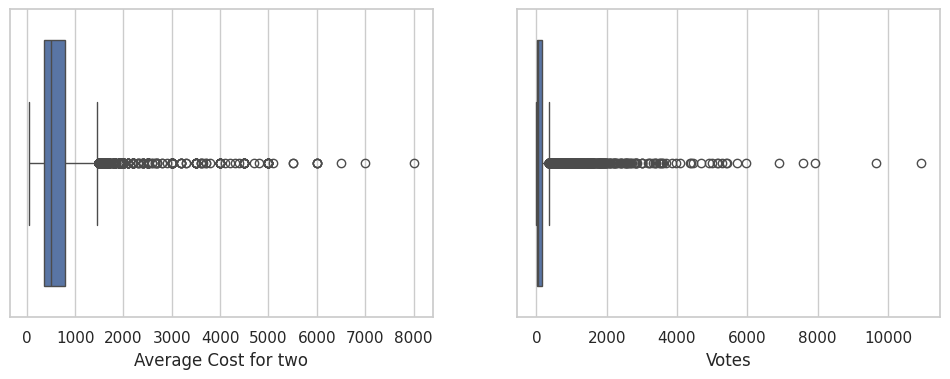

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['Average Cost for two'], ax=ax[0])
sns.boxplot(x=df['Votes'], ax=ax[1])
plt.show()

# IQR method
def cap_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return series.clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

df['Average Cost for two'] = cap_outliers(df['Average Cost for two'])
df['Votes'] = cap_outliers(df['Votes'])

Capping keeps all rows but limits extreme values.

# EDA (Exploratory Data Analysis)

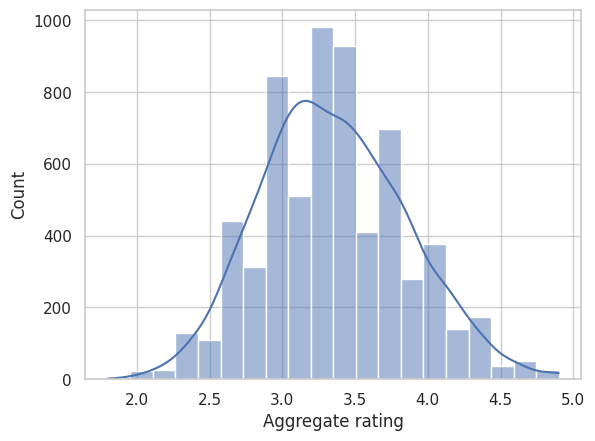

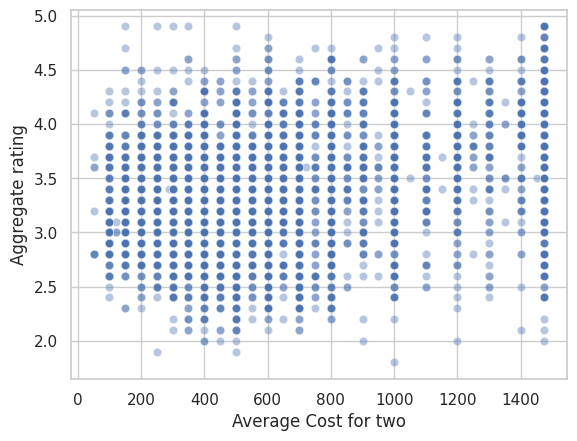

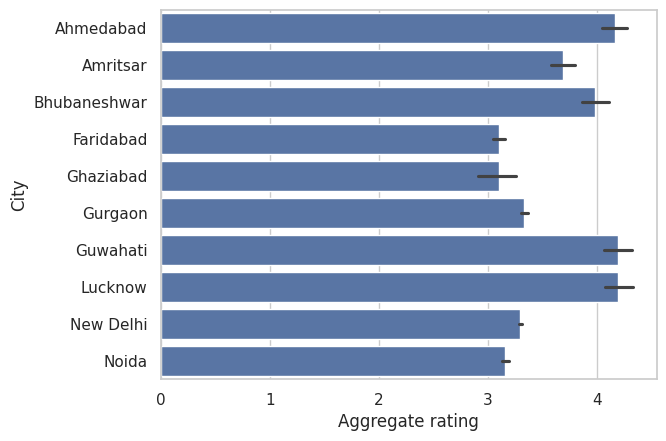

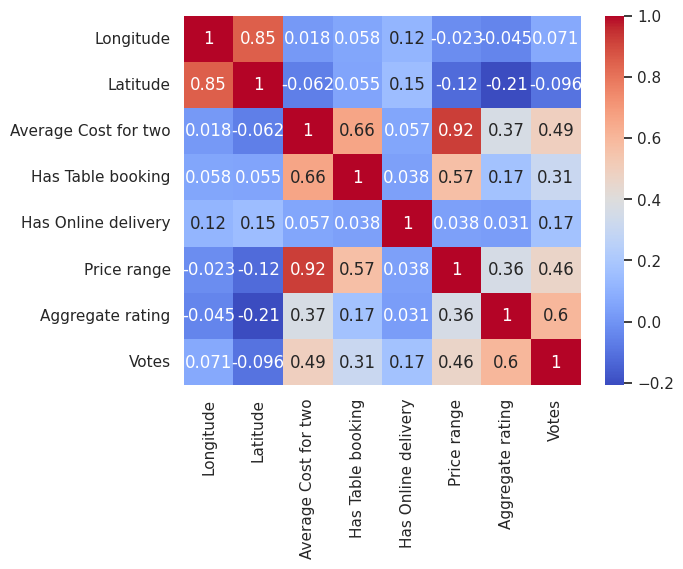

In [120]:
# Rating distribution
sns.histplot(df['Aggregate rating'], bins=20, kde=True)
plt.show()

# Cost vs rating
sns.scatterplot(x='Average Cost for two', y='Aggregate rating', data=df, alpha=0.4)
plt.show()

# Average rating by city (top 10 cities)
top_cities = df['City'].value_counts().head(10).index
sns.barplot(x='Aggregate rating', y='City',
            data=df[df['City'].isin(top_cities)], estimator=np.mean)
plt.show()

# Correlation heatmap
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm')
plt.show()

Advance EDA

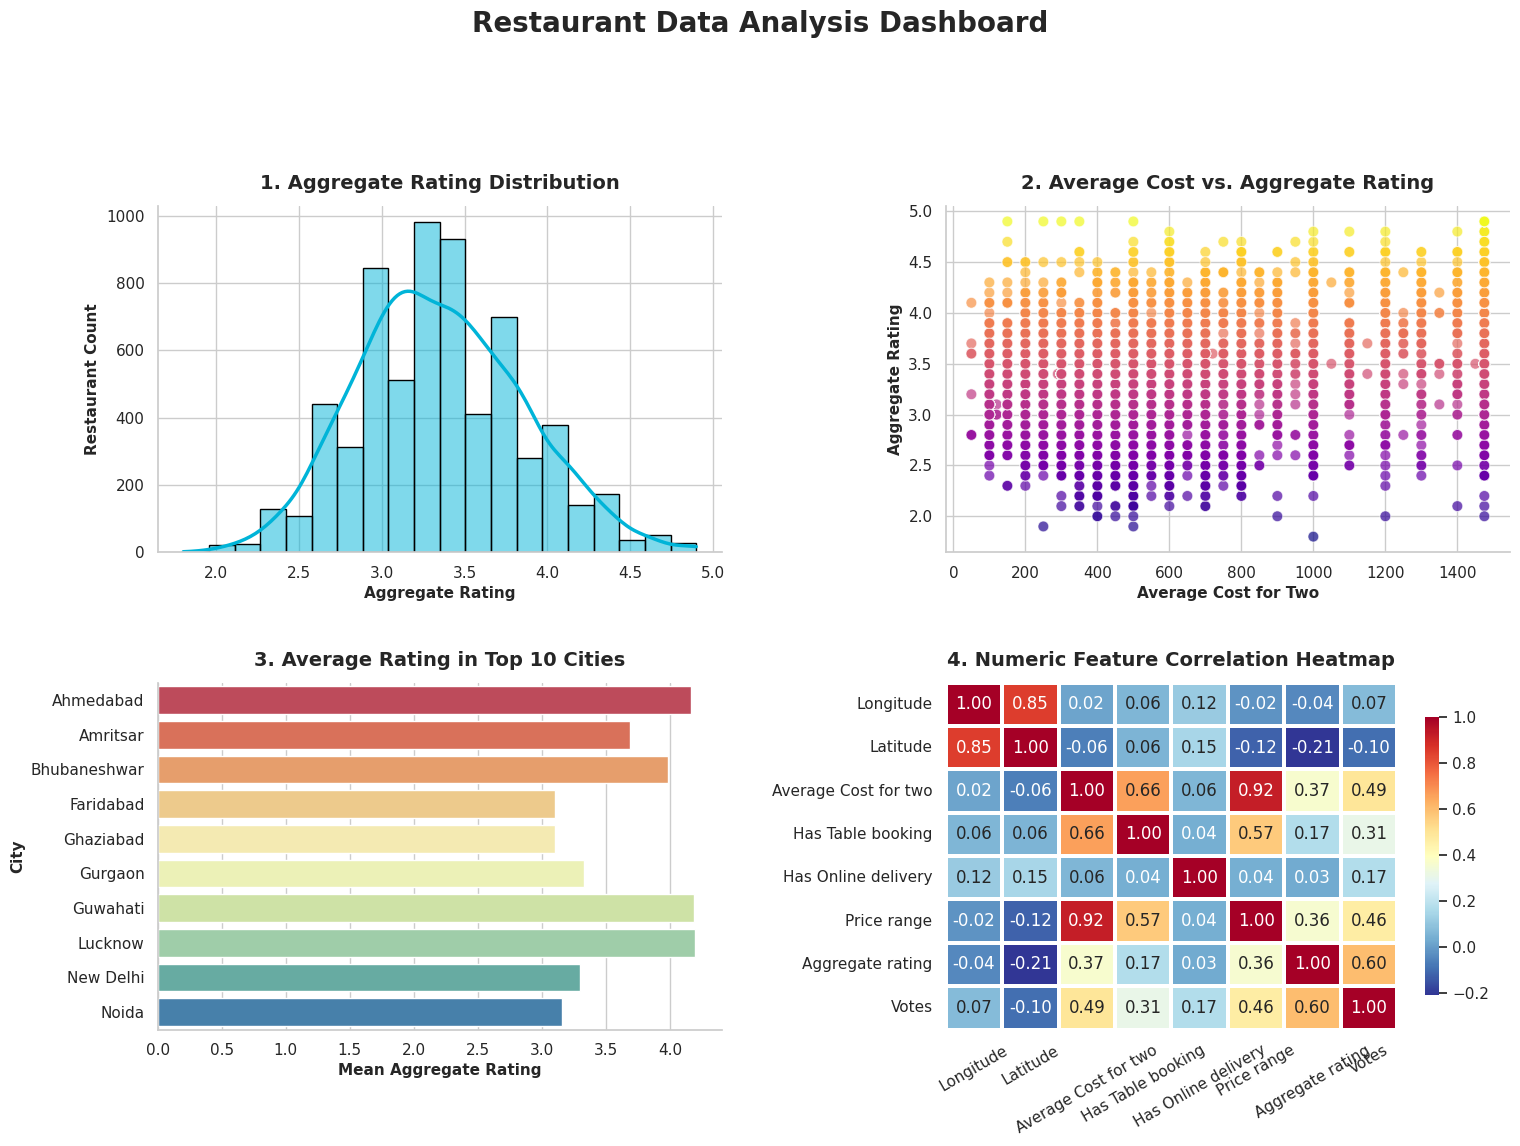

In [121]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Set clean visual theme and create a large 2x2 dashboard grid
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Restaurant Data Analysis Dashboard', fontsize=20, fontweight='bold', y=0.98)

# =====================================================================
# PANEL 1 (Top-Left -> axes[0, 0]): Rating Distribution
# =====================================================================
sns.histplot(
    df['Aggregate rating'],
    bins=20,
    kde=True,
    color='#00B4D8',
    edgecolor='black',
    line_kws={'linewidth': 2.5},
    ax=axes[0, 0]  # <-- Fixed: row 0, col 0
)
axes[0, 0].set_title('1. Aggregate Rating Distribution', fontsize=14, fontweight='bold', pad=12)
axes[0, 0].set_xlabel('Aggregate Rating', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Restaurant Count', fontsize=11, fontweight='bold')

# =====================================================================
# PANEL 2 (Top-Right -> axes[0, 1]): Cost vs Rating
# =====================================================================
sns.scatterplot(
    x='Average Cost for two',
    y='Aggregate rating',
    data=df,
    hue='Aggregate rating',
    palette='plasma',
    alpha=0.7,
    s=60,
    legend=False,
    ax=axes[0, 1]  # <-- Fixed: row 0, col 1
)
axes[0, 1].set_title('2. Average Cost vs. Aggregate Rating', fontsize=14, fontweight='bold', pad=12)
axes[0, 1].set_xlabel('Average Cost for Two', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Aggregate Rating', fontsize=11, fontweight='bold')

# =====================================================================
# PANEL 3 (Bottom-Left -> axes[1, 0]): Top 10 Cities by Average Rating
# =====================================================================
top_cities = df['City'].value_counts().head(10).index
city_data = df[df['City'].isin(top_cities)]

sns.barplot(
    x='Aggregate rating',
    y='City',
    data=city_data,
    estimator=np.mean,
    hue='City',
    palette='Spectral',
    errorbar=None,
    legend=False,
    ax=axes[1, 0]  # <-- Fixed: row 1, col 0
)
axes[1, 0].set_title('3. Average Rating in Top 10 Cities', fontsize=14, fontweight='bold', pad=12)
axes[1, 0].set_xlabel('Mean Aggregate Rating', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('City', fontsize=11, fontweight='bold')

# =====================================================================
# PANEL 4 (Bottom-Right -> axes[1, 1]): Correlation Heatmap
# =====================================================================
corr_matrix = df.select_dtypes('number').corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'shrink': 0.8},
    ax=axes[1, 1]  # <-- Fixed: row 1, col 1
)
axes[1, 1].set_title('4. Numeric Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=12)
axes[1, 1].tick_params(axis='x', rotation=30)

# 2. Clean up borders and add generous spacing between all 4 charts
sns.despine(ax=axes[0, 0])
sns.despine(ax=axes[0, 1])
sns.despine(ax=axes[1, 0])

plt.tight_layout(rect=[0, 0, 1, 0.95], pad=3.0)
plt.show()


# Feature engineering

In [122]:
# 1. Number of cuisines served
df['num_cuisines'] = df['Cuisines'].apply(lambda x: len(x.split(',')))

# 2. Flags for the top 10 cuisines
top_cuisines = (df['Cuisines'].str.split(', ').explode().value_counts().head(10).index)
for c in top_cuisines:
    df['cuisine_' + c.replace(' ', '_')] = df['Cuisines'].apply(lambda x: int(c in x))

# 3. Chain restaurant (number of outlets with the same name)
df['outlets'] = df.groupby('Restaurant Name')['Restaurant Name'].transform('count')

# 4. Log of votes (reduces skew)
df['log_votes'] = np.log1p(df['Votes'])

# 5. Frequency encoding for City and Locality (many unique values)
df['city_freq'] = df['City'].map(df['City'].value_counts())
df['locality_freq'] = df['Locality'].map(df['Locality'].value_counts())

# Drop the original text columns
df = df.drop(columns=['Restaurant Name', 'City', 'Locality', 'Cuisines'])
print(df.columns.tolist())

['Longitude', 'Latitude', 'Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range', 'Aggregate rating', 'Votes', 'num_cuisines', 'cuisine_North_Indian', 'cuisine_Chinese', 'cuisine_Fast_Food', 'cuisine_Mughlai', 'cuisine_Continental', 'cuisine_Italian', 'cuisine_Cafe', 'cuisine_Bakery', 'cuisine_Desserts', 'cuisine_South_Indian', 'outlets', 'log_votes', 'city_freq', 'locality_freq']


# Split features and target, then Train-Test Split

In [123]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Aggregate rating'])
y = df['Aggregate rating']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (5203, 22) Test: (1301, 22)


# Model selection

In [124]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [125]:
models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LinearRegression()),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy='median'),
        DecisionTreeRegressor(max_depth=5, random_state=42)),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestRegressor(n_estimators=100, max_depth=10,
                              random_state=42, n_jobs=-1)),

    "KNN": make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5))
}

results = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    results.append({'Model': name, 'CV R2': round(scores.mean(), 3)})

comparison = pd.DataFrame(results).sort_values(by='CV R2', ascending=False)
print(comparison)

               Model  CV R2
2      Random Forest  0.547
0  Linear Regression  0.494
1      Decision Tree  0.455
3                KNN  0.421


# Model training

In [126]:
final = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    final.append({
        'Model': name,
        'MAE': round(mean_absolute_error(y_test, pred), 3),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, pred)), 3),
        'R2': round(r2_score(y_test, pred), 3)
    })

final_df = pd.DataFrame(final).sort_values(by='R2', ascending=False)
print(final_df)

# Pick the best model automatically
best_name = final_df.iloc[0]['Model']
best_model = models[best_name]
print("Best model:", best_name)

               Model    MAE   RMSE     R2
2      Random Forest  0.249  0.329  0.573
0  Linear Regression  0.266  0.352  0.513
1      Decision Tree  0.272  0.357  0.498
3                KNN  0.286  0.383  0.422
Best model: Random Forest


In [127]:
y_pred = best_model.predict(X_test)

print("MAE :", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R2  :", round(r2_score(y_test, y_pred), 3))

MAE : 0.249
RMSE: 0.329
R2  : 0.573


# Hyperparameter tuning

This tunes Random Forest inside the pipeline. The parameter names need the randomforestregressor__ prefix.

In [128]:
rf_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(random_state=42, n_jobs=-1))

params = {
    'randomforestregressor__n_estimators': [100, 200],
    'randomforestregressor__max_depth': [10, 20, None],
    'randomforestregressor__min_samples_split': [2, 5]
}

grid = GridSearchCV(rf_pipe, params, cv=3, scoring='r2')
grid.fit(X_train, y_train)
print("Best settings:", grid.best_params_)
best_model = grid.best_estimator_

Best settings: {'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_split': 5, 'randomforestregressor__n_estimators': 200}


# Output and feature importance

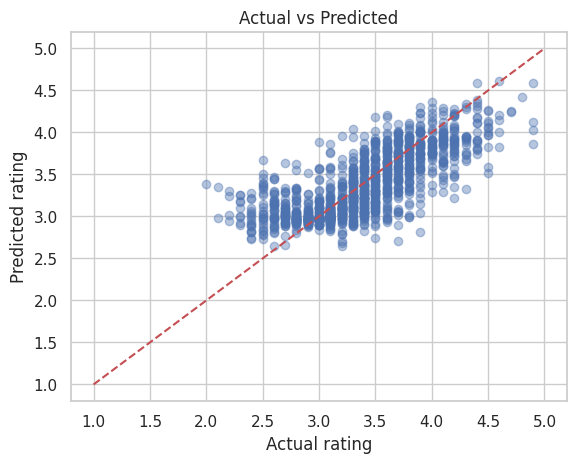

                 Feature  Importance
19             log_votes    0.238322
6                  Votes    0.228417
0              Longitude    0.089237
1               Latitude    0.083786
18               outlets    0.058579
21         locality_freq    0.056228
20             city_freq    0.055814
2   Average Cost for two    0.052028
9        cuisine_Chinese    0.024266
7           num_cuisines    0.020787


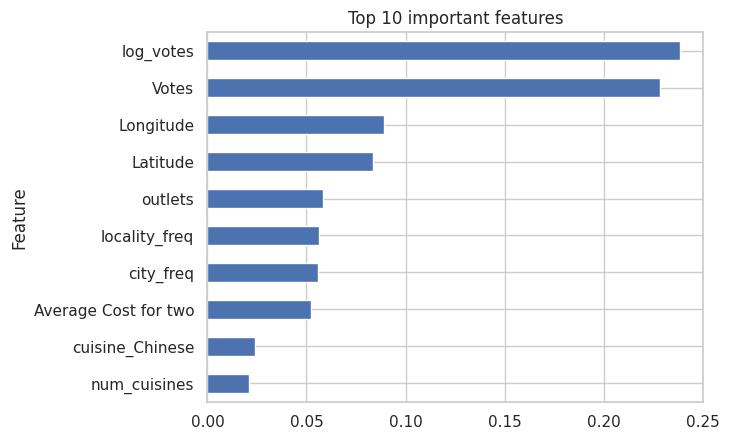

In [129]:
y_pred = best_model.predict(X_test)

# Actual vs predicted
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([1, 5], [1, 5], 'r--')
plt.xlabel("Actual rating"); plt.ylabel("Predicted rating")
plt.title("Actual vs Predicted")
plt.show()

# Feature importance (Random Forest)
rf = best_model.named_steps['randomforestregressor']
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance_df.head(10))
importance_df.head(10).plot(kind='barh', x='Feature', y='Importance',
                            legend=False, title="Top 10 important features")
plt.gca().invert_yaxis()
plt.show()

Top 10 Important Features:
                  Feature  Importance
19             log_votes    0.238322
6                  Votes    0.228417
0              Longitude    0.089237
1               Latitude    0.083786
18               outlets    0.058579
21         locality_freq    0.056228
20             city_freq    0.055814
2   Average Cost for two    0.052028
9        cuisine_Chinese    0.024266
7           num_cuisines    0.020787


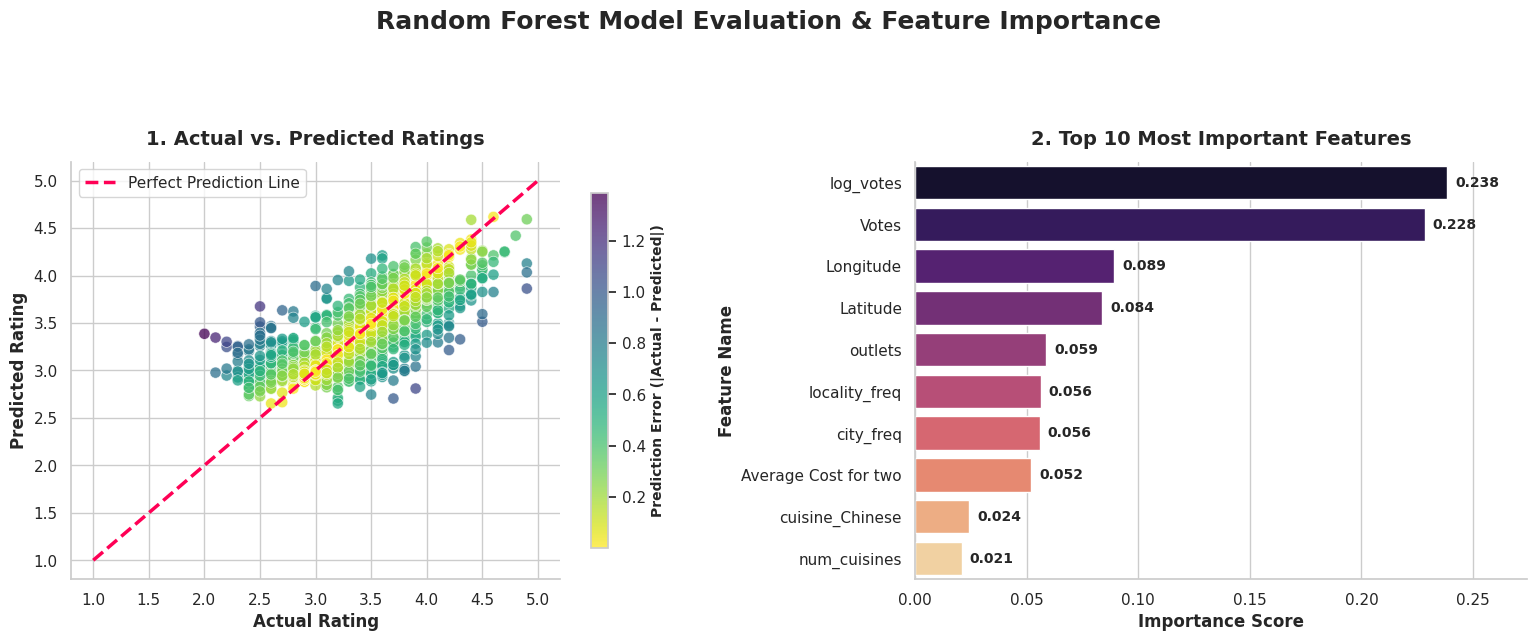

In [130]:
# 1. Generate predictions and extract top 10 feature importances
y_pred = best_model.predict(X_test)
rf = best_model.named_steps['randomforestregressor']

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 Important Features:\n", importance_df.head(10))

# 2. Create a spacious 1x2 dashboard layout
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
fig.suptitle('Random Forest Model Evaluation & Feature Importance', fontsize=18, fontweight='bold', y=1.02)

# =====================================================================
# LEFT PANEL (axes[0]): Actual vs. Predicted Ratings (Error-Colored)
# =====================================================================
# Calculate prediction error so dots closest to the line glow green/teal
errors = np.abs(y_test - y_pred)

scatter = axes[0].scatter(
    y_test,
    y_pred,
    c=errors,               # Colors dots based on prediction accuracy
    cmap='viridis_r',       # Bright yellow/green = accurate, dark purple = larger error
    alpha=0.75,
    edgecolors='white',
    linewidth=0.5,
    s=65
)

# Add the ideal 45-degree reference line
axes[0].plot([1, 5], [1, 5], color='#FF0055', linestyle='--', linewidth=2.5, label='Perfect Prediction Line')

# Add a colorbar explaining the error colors
cbar = plt.colorbar(scatter, ax=axes[0], shrink=0.85)
cbar.set_label('Prediction Error (|Actual - Predicted|)', fontsize=10, fontweight='bold')

axes[0].set_title('1. Actual vs. Predicted Ratings', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Actual Rating', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Predicted Rating', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left', fontsize=11)

# =====================================================================
# RIGHT PANEL (axes[1]): Top 10 Important Features (Colorful Bars)
# =====================================================================
top_10_features = importance_df.head(10)

sns.barplot(
    data=top_10_features,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='magma',        # Rich purple-red-orange gradient
    legend=False,
    ax=axes[1]
)

# Add exact importance percentage/score labels next to each bar
for i, val in enumerate(top_10_features['Importance']):
    axes[1].text(
        val + (top_10_features['Importance'].max() * 0.015),
        i,
        f'{val:.3f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

axes[1].set_title('2. Top 10 Most Important Features', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Importance Score', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Feature Name', fontsize=12, fontweight='bold')
axes[1].set_xlim(0, top_10_features['Importance'].max() * 1.15) # Room for text labels

# 3. Clean up borders and add spacing between the two panels
sns.despine(ax=axes[0])
sns.despine(ax=axes[1])

plt.tight_layout(pad=2.5)
plt.show()


In [131]:
import joblib

# Save your trained model to a file
joblib.dump(best_model, "zomato_rating_model.pkl")
print("Model saved successfully!")


Model saved successfully!


# Quick Example:
Create a brand-new Python file (like predict.py) in the same folder as your .pkl file and run this:

In [132]:
import joblib
import pandas as pd

# 1. Load your saved model
model = joblib.load("zomato_rating_model.pkl")

# 2. Create a blank template matching X_train's exact columns (all set to 0)
new_restaurant = pd.DataFrame(0, index=[0], columns=X_train.columns)

# 3. Fill in the specific restaurant details you want to test
new_restaurant["Average Cost for two"] = 800
new_restaurant["Votes"] = 150
new_restaurant["Has Online delivery"] = 1
new_restaurant["Has Table booking"] = 0
new_restaurant["Price range"] = 2
new_restaurant["Latitude"] = 28.6139
new_restaurant["Longitude"] = 77.2090

# Optional: Set a specific cuisine column to 1 if it exists
if "cuisine_Bakery" in new_restaurant.columns:
    new_restaurant["cuisine_Bakery"] = 1

# 4. Predict the rating (use [0] to extract the single number from the array)
predicted_rating = model.predict(new_restaurant)[0]
print(f"Predicted Zomato Rating: {predicted_rating:.2f} / 5.0")


Predicted Zomato Rating: 3.58 / 5.0
